# Proyecto 3 — Pasos 1 a 4: análisis de la solución secuencial y diseño paralelo
**CC3069 · UVG · Semestre II 2026**

| Paso | Qué se hace | Dónde está |
|---|---|---|
| **1** | Análisis de la solución secuencial existente (Laboratorio 3) | §1 · `docs/01_analisis_secuencial.md` |
| **2** | Medición del tiempo de ejecución secuencial | §2 · `docs/02_medicion_secuencial.md` |
| **3** | Identificación de oportunidades de paralelización | §3 · `docs/03_oportunidades_paralelizacion.md` |
| **4** | Diseño del algoritmo paralelo con CUDA | §4 · `docs/04_diseno_algoritmo_paralelo.md` |

Los pasos 5 (implementación con CUDA Python) y 6 (análisis y conclusiones) no están en este notebook.

In [1]:
import sys, ast, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Markdown, Image, display
from comun import config

LAB = ROOT / "secuencial" / "lab3_original"      # código del Laboratorio 3, sin modificar

def source_of(path, name):
    """Código fuente de una función dentro de un archivo (sin importarlo)."""
    text = Path(path).read_text(encoding="utf-8")
    for n in ast.parse(text).body:
        if isinstance(n, ast.FunctionDef) and n.name == name:
            return ast.get_source_segment(text, n)

import re

def mostrar_doc(nombre, desde=None):
    """Muestra un documento .md del proyecto, incrustando sus imágenes dentro del notebook."""
    base = ROOT / "docs"
    t = (base / nombre).read_text(encoding="utf-8")
    if desde:
        t = t[t.index(desde):]
    pos = 0
    for m in re.finditer(r"!\[([^\]]*)\]\(([^)]+)\)", t):
        display(Markdown(t[pos:m.start()]))
        display(Image(filename=str((base / m.group(2)).resolve())))
        pos = m.end()
    display(Markdown(t[pos:]))

## 1. Análisis de la solución secuencial existente (Paso 1)
Solución analizada: **Laboratorio 3** (Keras/TensorFlow).

### 1.1 Código de las partes principales
**Preparación de cada imagen** (`secuencial/lab3_original/preprocessing.py`):

In [2]:
print(source_of(LAB / "preprocessing.py", "preprocess_image"))
print(source_of(LAB / "preprocessing.py", "load_preprocessed_batch"))

def preprocess_image(
    image_path: Path,
    image_size: tuple[int, int] = DEFAULT_IMAGE_SIZE,
) -> np.ndarray:
    """Carga una imagen como RGB, la reduce y normaliza sus píxeles a [0, 1]."""
    width, height = image_size
    if width <= 0 or height <= 0:
        raise ValueError("Las dimensiones de salida deben ser positivas")

    with Image.open(image_path) as image:
        rgb = image.convert("RGB")
        resized = rgb.resize(image_size, Image.Resampling.LANCZOS)
        array = np.asarray(resized, dtype=np.float32) / 255.0
    return array
def load_preprocessed_batch(
    manifest: pd.DataFrame,
    image_root: Path,
    image_size: tuple[int, int] = DEFAULT_IMAGE_SIZE,
) -> tuple[np.ndarray, np.ndarray]:
    """Carga un subconjunto pequeño como arreglos NumPy para análisis o prueba."""
    validate_manifest(manifest)
    root = Path(image_root)
    images = [preprocess_image(root / row.path, image_size) for row in manifest.itertuples()]
    return np.stack(images), manife

**Modelo CNN #2** (`secuencial/lab3_original/models.py`):

In [3]:
print(source_of(LAB / "models.py", "build_cnn_regularized"))

def build_cnn_regularized(
    input_shape: tuple[int, int, int] = DEFAULT_INPUT_SHAPE,
    num_classes: int = NUM_CLASSES,
) -> keras.Model:
    """CNN más profunda con BatchNorm y Dropout para controlar overfitting.

    Tres bloques conv-conv-pool con normalización por lotes, seguidos de
    una capa densa con dropout fuerte antes de la salida.
    """
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape),
            layers.Conv2D(32, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.Conv2D(32, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),
            layers.Dropout(0.25),
            layers.Conv2D(64, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.Conv2D(64, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),
            la

### 1.2 Tablas del paso 1

In [4]:
mostrar_doc("01_analisis_secuencial.md", desde="## 1.1")

## 1.1 Partes principales del programa y su función

| Parte | Archivo | Función |
|---|---|---|
| Carga y muestreo | `data_loading.py` | Toma 600 imágenes por clase (17,400 de 87,000) |
| Preparación | `preprocessing.py` | Divide en entrenamiento / validación / prueba (70 / 15 / 15 %) y convierte cada imagen en un arreglo 64 × 64 × 3 |
| Modelos | `models.py` | Define CNN #1, CNN #2, MLP y Random Forest |
| Aumento de datos | `augmentation.py` | Transformaciones aleatorias que no cambian la letra |
| Entrenamiento y evaluación | notebooks 04–09 | Entrena con Adam (lote de 64, hasta 30 épocas), valida en cada época y evalúa en prueba |

## 1.2 Descomposición en operaciones

**Tabla 1.** Operaciones, desde la recepción de las imágenes hasta el resultado.

| No. | Operación identificada | Descripción de su funcionamiento |
|---|---|---|
| 1 | Muestreo y partición | Elige 600 imágenes por clase y las reparte en entrenamiento (12,180), validación (2,610) y prueba (2,610). Se hace una sola vez |
| 2 | Lectura del archivo | Abre el archivo JPG desde el disco |
| 3 | Decodificación del JPEG | Obtiene la matriz de píxeles de 200 × 200 × 3 |
| 4 | Conversión a RGB | Garantiza tres canales de color |
| 5 | Reducción de resolución | Interpolación Lanczos de 200 × 200 a 64 × 64 |
| 6 | Normalización | Divide los valores entre 255 (rango 0 a 1) |
| 7 | Apilado y etiquetado | Junta las imágenes en un tensor `(N, 64, 64, 3)` y convierte cada letra en un número (0–28) |
| 8 | Aumento de datos *(solo en los reentrenamientos con augmentation)* | Aplica una transformación aleatoria a cada imagen de entrenamiento en cada época |
| 9 | Convolución + ReLU | Filtros de 3 × 3 deslizados sobre la imagen; cada valor de salida es una suma de productos |
| 10 | BatchNorm, Dropout y pooling | Normaliza por canal, apaga neuronas al azar y reduce el mapa a la mitad (máximo de cada 2 × 2) |
| 11 | Capas densas y softmax | Multiplica por matrices de pesos y produce 29 probabilidades |
| 12 | Función de pérdida | Entropía cruzada entre la predicción y la letra real, promediada sobre el lote |
| 13 | Retropropagación | Gradiente de la pérdida respecto a cada peso, de la salida a la entrada |
| 14 | Actualización de pesos | El optimizador Adam corrige cada peso con su gradiente |
| 15 | Evaluación en validación | Al final de cada época calcula el accuracy en validación y decide la parada temprana |
| 16 | Predicción en prueba | Predice las 2,610 imágenes de prueba: accuracy y matriz de confusión (resultado final) |
| 17 | Random Forest *(modelo alterno)* | Entrena 400 árboles sobre los 12,288 píxeles aplanados |

## 1.3 Operaciones repetitivas

Datos: 12,180 imágenes de entrenamiento, lotes de 64 → **191 lotes por época**, hasta 30 épocas por modelo.

**Tabla 2.** Operaciones que se ejecutan repetidamente.

| Operación repetitiva | Datos que procesa | Cantidad de repeticiones |
|---|---|---|
| Leer, decodificar, reducir y normalizar una imagen (ops. 2–6) | Un JPG de 200 × 200 × 3 → arreglo de 64 × 64 × 3 | **17,400** por ejecución (una por imagen, independientes entre sí) |
| Paso de entrenamiento: adelante, pérdida, atrás y Adam (ops. 9–14) | Un lote de 64 imágenes | **191 por época**; hasta 5,730 por modelo (191 × 30) |
| Convolución 3 × 3 (op. 9) | Cada valor de cada mapa de salida: un producto punto de `3 × 3 × canales` valores | Por imagen y por paso. CNN #2: ≈ **118.9 M** multiplicaciones-acumulaciones por imagen (CNN #1: 24.5 M; MLP: 6.4 M) |
| Actualización de pesos Adam (op. 14) | Cada parámetro: 2.1 M (CNN #1), 2.2 M (CNN #2), 6.4 M (MLP) | Una vez por paso de entrenamiento |
| Evaluación en validación (op. 15) | 2,610 imágenes | Una vez por época |
| Predicción en prueba (op. 16) | 2,610 imágenes | Una vez por modelo |
| Aumento de datos (op. 8) | Cada imagen de entrenamiento | 12,180 por época |


## 2. Medición del tiempo de ejecución secuencial (Paso 2)
Procedimiento, resultados, análisis y factores. Datos crudos: `results/benchmark_pc1_keras_original.csv`.

## 2.1 Qué se midió y con qué equipo

**Conjunto de imágenes:** las 17,400 de la muestra del Lab 3 (12,180 entrenamiento, 2,610 validación, 2,610 prueba).

| Tarea | Código del Lab 3 | Imágenes |
|---|---|---:|
| Preparar las imágenes | `load_preprocessed_batch` (una por una) | 17,400 |
| Entrenar | `model.fit` de CNN #1, CNN #2 y MLP (3 épocas fijas, lote de 64) | 12,180 × 3 épocas |
| Evaluar en test | `model.evaluate` | 2,610 |

**Equipo:** Intel Core i7-10750H (6 núcleos / 12 hilos) · 15.8 GB de RAM · Windows 11 · Python 3.12 · TensorFlow 2.21.
TensorFlow en Windows nativo no usa la GPU, así que todo corre en CPU.

## 2.2 Procedimiento

1. Equipo enchufado y sin programas pesados abiertos. Antes de medir se lee una vez cada archivo, para que el disco no afecte.
2. Cada tarea se mide con `time.perf_counter()`.
3. Se **repite 3 veces** en las mismas condiciones (misma semilla, datos e hiperparámetros) y se calcula media y desviación estándar.
4. Se registra el uso de cada núcleo del CPU cada 0.5 s (`logs/resources_pc1_keras_original.csv`).

*(Un primer intento se interrumpió por falta de memoria; se cerraron programas y se repitió completo.)*

## 2.3 Resultados

Tiempo en segundos. Tabla en `results/secuencial_tabla_pc1.md`; datos crudos en `results/benchmark_pc1_keras_original.csv`.

| Tarea | Rep. 1 | Rep. 2 | Rep. 3 | **Media ± desv.** | ms por imagen |
|---|---:|---:|---:|---:|---:|
| Preparar las imágenes | 16.84 | 17.05 | 17.36 | **17.09 ± 0.26** | 0.98 |
| Entrenar CNN #1 | 29.83 | 31.97 | 32.03 | **31.27 ± 1.25** | 0.86 |
| Entrenar CNN #2 | 188.60 | 193.28 | 195.34 | **192.41 ± 3.45** | 5.27 |
| Entrenar MLP | 25.50 | 25.14 | 25.67 | **25.44 ± 0.27** | 0.70 |
| Evaluar en test CNN #1 | 0.54 | 0.58 | 0.59 | **0.57 ± 0.03** | 0.22 |
| Evaluar en test CNN #2 | 2.28 | 2.33 | 2.37 | **2.32 ± 0.04** | 0.89 |
| Evaluar en test MLP | 0.19 | 0.20 | 0.19 | **0.20 ± 0.00** | 0.08 |
| **TOTAL** | 263.78 | 270.54 | 273.55 | **269.29 ± 5.00** | |

*«ms por imagen» = tiempo medio ÷ imágenes procesadas; en entrenar incluye la validación de cada época.*



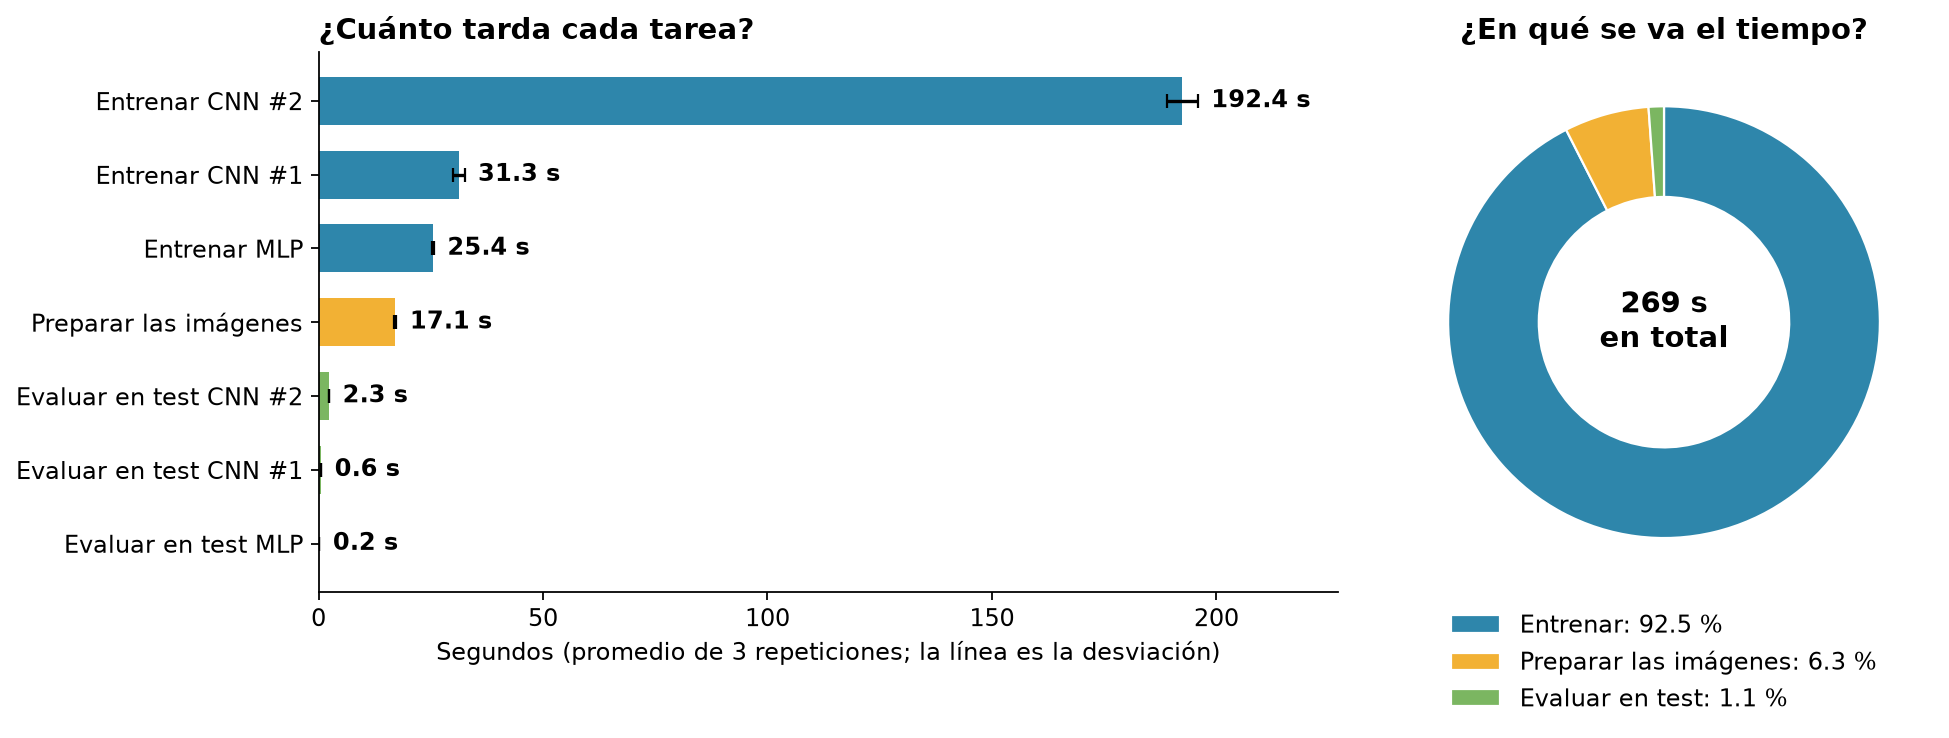

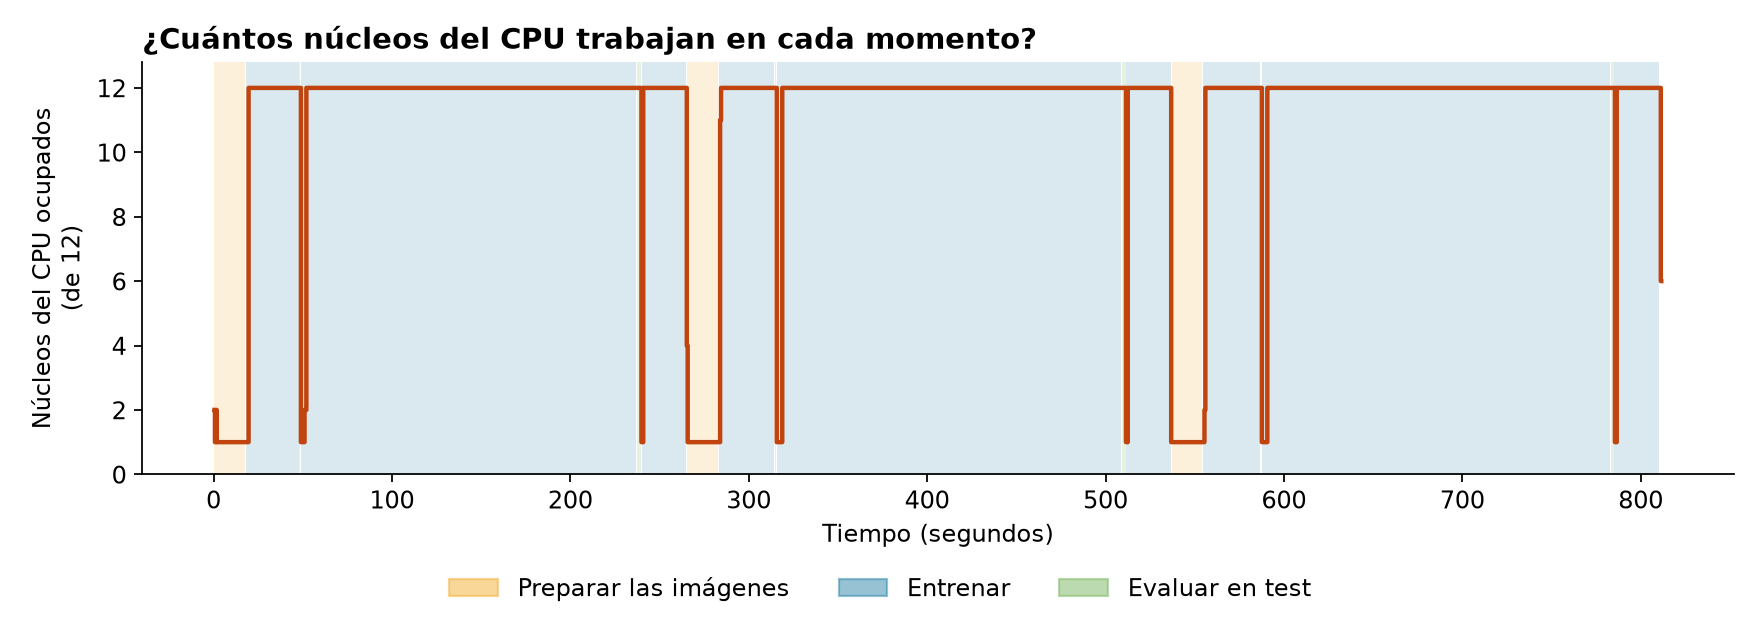



**Evidencia de ejecución** (capturas del monitor de recursos durante una corrida del mismo código; detalle en
[`results/evidencia/`](../results/evidencia/README.md)):



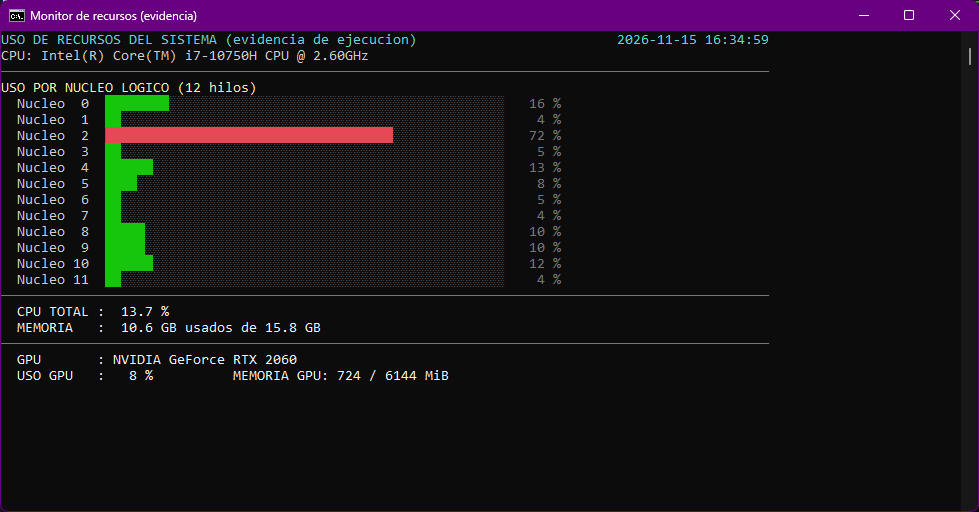

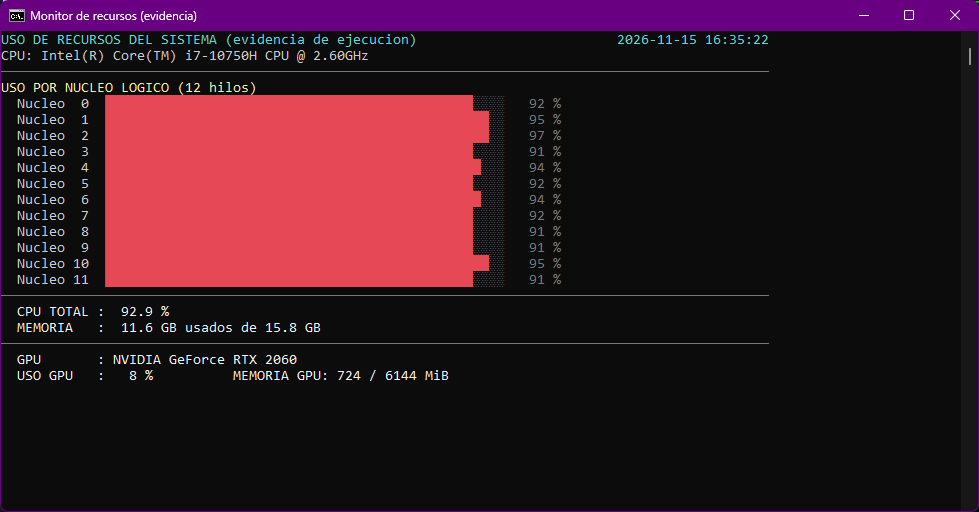



## 2.4 Análisis de los tiempos

* **Entrenar es el 92.5 % del tiempo** (249 de 269 s); la **CNN #2 sola es el 71 %** (192 s).
* **Preparar las imágenes es el 6.3 %** (17 s, 0.98 ms por imagen) y usa **1 núcleo de 12**; entrenar usa los 12.
* **Evaluar en test es el 1.1 %** (3 s).
* **Los resultados son estables:** la desviación es de 0 a 5 % por tarea y 1.9 % en el total.

## 2.5 Factores que podrían influir en el rendimiento

| Factor | Efecto |
|---|---|
| Núcleos usados | Preparar imágenes usa 1 de 12 núcleos; entrenar usa los 12 |
| Costo del modelo | CNN #2 ≈ 118.9 M multiplicaciones por imagen: 4.9× la CNN #1 y 18× el MLP |
| Lectura de disco y decodificación JPEG | Afecta la preparación; por eso se precarga cada archivo antes de medir |
| Tamaño de lote y número de épocas | Fijos (64 y 3); más épocas aumentan el tiempo casi proporcionalmente |
| Memoria disponible | 17,400 imágenes normalizadas ocupan 0.85 GB; con poca RAM el sistema interrumpió un intento |
| Carga del sistema y temperatura | Antivirus, otros programas y límite térmico del portátil causan la pequeña variación entre repeticiones |
| Hardware sin aprovechar | La GPU del equipo no participa: TensorFlow en Windows solo usa CPU |


In [5]:
mostrar_doc("02_medicion_secuencial.md", desde="## 2.1")

### 2.x Código que realizó la medición
Ejecuta el código del Lab 3 sin modificarlo y mide cada tarea con `time.perf_counter()`, 3 repeticiones
(`secuencial/medir_secuencial.py`). Fragmento del ciclo de medición:

In [6]:
texto = (ROOT / "secuencial" / "medir_secuencial.py").read_text(encoding="utf-8")
ini = texto.index("for rep in range(1, args.reps + 1):")
fin = texto.index("mark(\"idle\")")
print(texto[ini:fin])

for rep in range(1, args.reps + 1):
            print(f"\n--- Repetición {rep}/{args.reps} ---")
            mark(f"preprocess_r{rep}")
            t0 = time.perf_counter()
            images, labels = lab_prep.load_preprocessed_batch(manifest, TRAIN_DIR)   # código original, NHWC
            record(rep, "preprocess", "-", time.perf_counter() - t0, images=len(manifest))
            y_all = np.array([index[x] for x in labels], dtype=np.int64)
            split = manifest["split"].to_numpy()
            x_tr, y_tr = images[split == "train"], y_all[split == "train"]
            x_va, y_va = images[split == "validation"], y_all[split == "validation"]
            x_te, y_te = images[split == "test"], y_all[split == "test"]
            del images  # libera ~0.85 GB: evita tener el dataset duplicado en RAM junto a TensorFlow

            for name in args.models:
                tf.keras.utils.set_random_seed(SEED)
                tf.keras.backend.clear_session()
                model = builde

## 3. Identificación de oportunidades de paralelización (Paso 3)

In [7]:
mostrar_doc("03_oportunidades_paralelizacion.md", desde="Los pasos 1 y 2")

Los pasos 1 y 2 muestran que el entrenamiento (operaciones 9 a 15 de la Tabla 1) es el **92.5 %** del tiempo.

## Operaciones que se proponen paralelizar con CUDA y cómo se benefician

| Operación (Tabla 1) | Qué se ejecuta de forma simultánea | Cómo se beneficia de la GPU |
|---|---|---|
| **9. Convolución + ReLU** | Cada valor de salida, que no depende de los demás (8,388,608 en la capa mayor de la CNN #2, con lote de 64) | Millones de productos punto independientes, con mucha aritmética y acceso regular a memoria |
| **10. BatchNorm, Dropout y pooling** | Cada elemento del tensor (BatchNorm: una reducción por canal) | Operaciones simples sobre millones de elementos; aprovecha el gran ancho de banda de memoria de la GPU |
| **11. Capas densas y softmax** | Cada valor de la matriz resultante | Multiplicación de matrices: la operación para la que está diseñada la GPU |
| **12. Función de pérdida** | Una entropía cruzada por imagen del lote (64) y su promedio | Las 64 pérdidas se calculan a la vez |
| **13. Retropropagación** | Misma estructura que la propagación hacia adelante (≈ 2 veces su trabajo) | Duplica el trabajo paralelizable de cada paso |
| **14. Actualización de pesos (Adam)** | Cada parámetro (2.1 a 6.4 millones), sin dependencias entre ellos | Millones de actualizaciones simultáneas |
| **15–16. Evaluación y predicción** | Los mismos cálculos de la propagación hacia adelante; lotes independientes | Reutiliza los kernels anteriores con los datos ya en la memoria de la GPU |

**Idea clave:** el paralelismo está *dentro* de cada paso (entre los valores de cada capa), no *entre* pasos: cada
paso de entrenamiento necesita los pesos que dejó el anterior, así que los 191 lotes de una época no pueden
ejecutarse a la vez.

## Operaciones que no se llevan a CUDA

| Operación (Tabla 1) | Dónde se ejecuta | Justificación |
|---|---|---|
| **2–7. Preparar las imágenes** | CPU, repartido entre sus núcleos (cada imagen es independiente) | La GPU no abre archivos; decodificar JPEG tiene muchas bifurcaciones y poca aritmética; se hace una sola vez y pesa el 6.3 % del tiempo |
| 1, control de épocas y parada temprana | CPU | Se ejecutan una vez o son decisiones secuenciales |
| 17. Random Forest | CPU | No es una red neuronal; sus árboles ya usan todos los núcleos |


## 4. Diseño del algoritmo paralelo (Paso 4)

Propuesta con CUDA basada en las operaciones elegidas en el Paso 3: las imágenes se preparan en el CPU y la
matemática de la red se ejecuta en la GPU, con una sola copia de datos entre ambas.



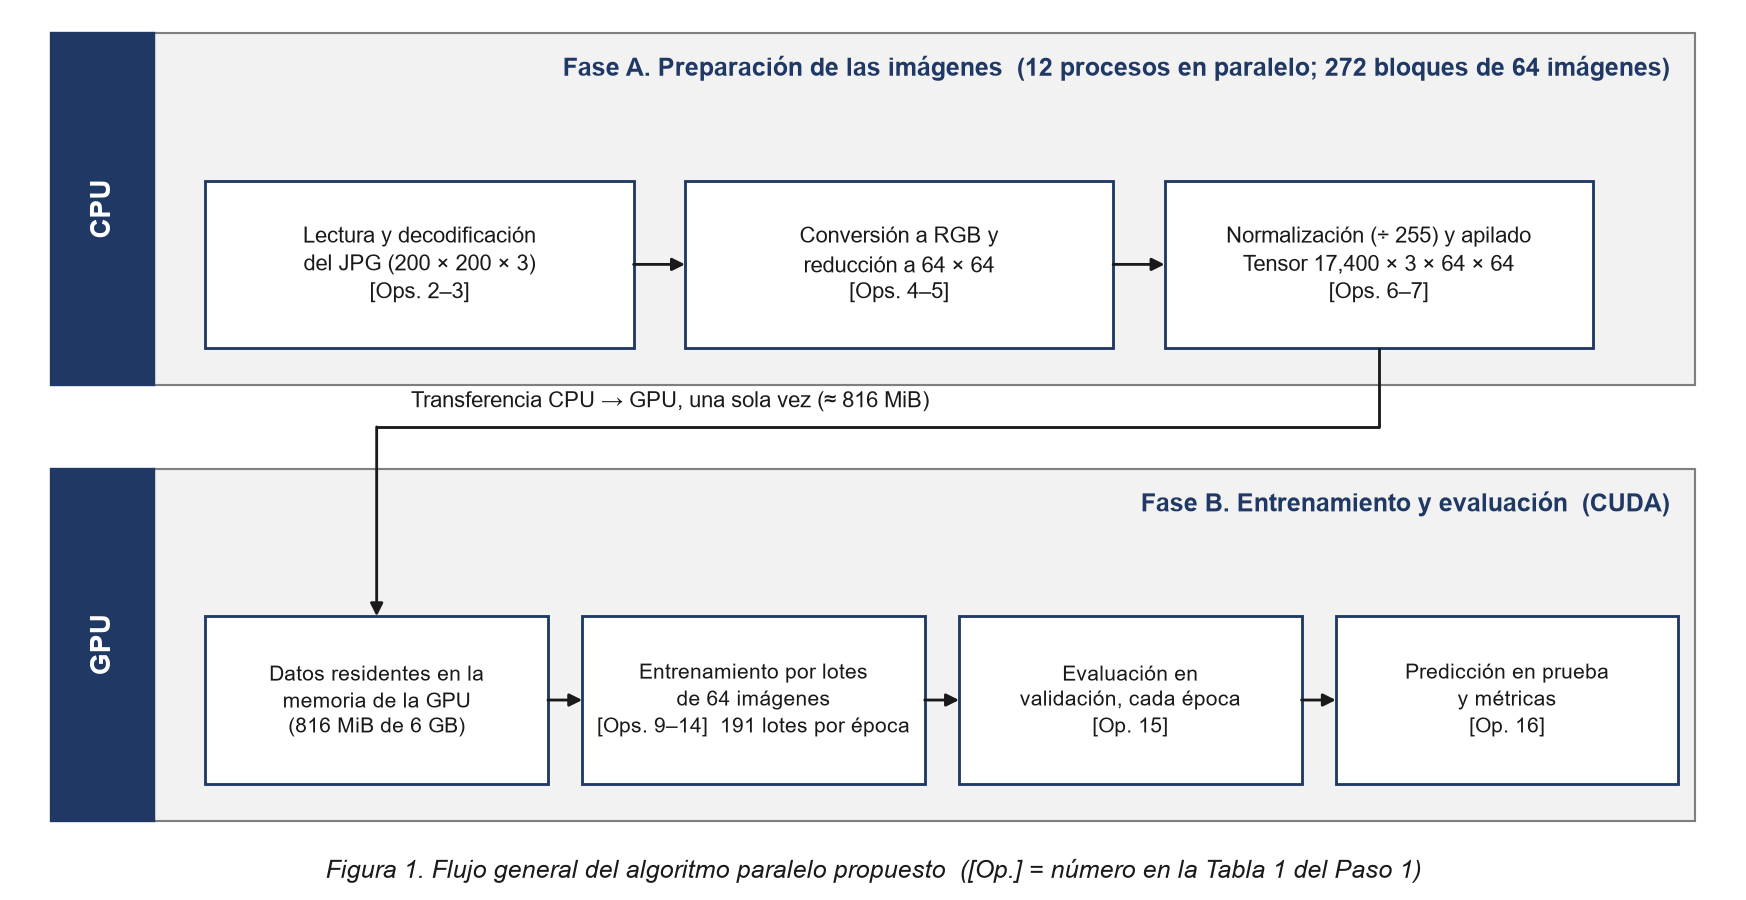



## 4.1 Fase A (CPU): reparto de las imágenes

* **Tareas:** bloques de 64 imágenes → `⌈17,400 / 64⌉ = 272` tareas independientes.
* **Ejecutores:** un proceso por hilo del CPU (12). Cada uno toma la siguiente tarea libre (≈ 22 por proceso).
* **Resultado:** los bloques se juntan en el mismo orden y se normalizan; la salida es idéntica a la del programa secuencial.

## 4.2 Puente: una sola copia CPU → GPU

17,400 × 3 × 64 × 64 valores de 4 bytes ≈ **816 MiB** (entrenamiento 571, validación 122, prueba 122), que caben en
los 6 GB de la GPU. Cada lote se toma después de la memoria de la GPU por índice, sin copias dentro del entrenamiento.

## 4.3 Fase B (GPU): un paso de entrenamiento



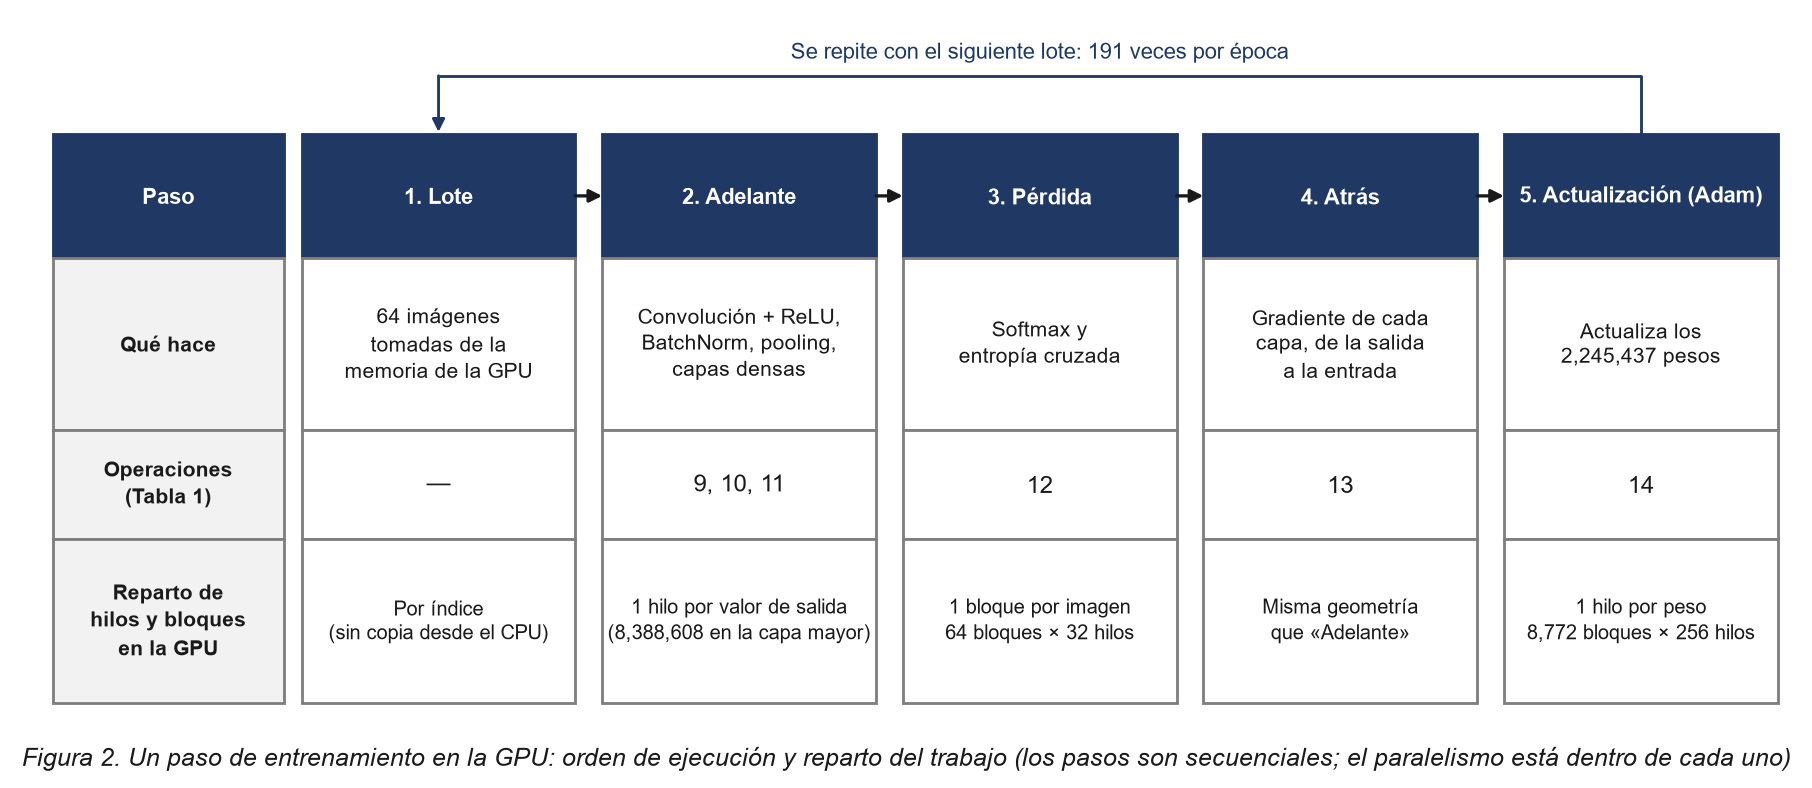



## 4.4 Distribución del trabajo entre hilos, bloques y grids

**Regla:** el tensor de salida de cada operación es el dominio del paralelismo; **cada valor de salida lo calcula un
hilo**, porque los valores de una misma capa son independientes. Los hilos se agrupan en bloques de 256 y los
bloques forman el grid.



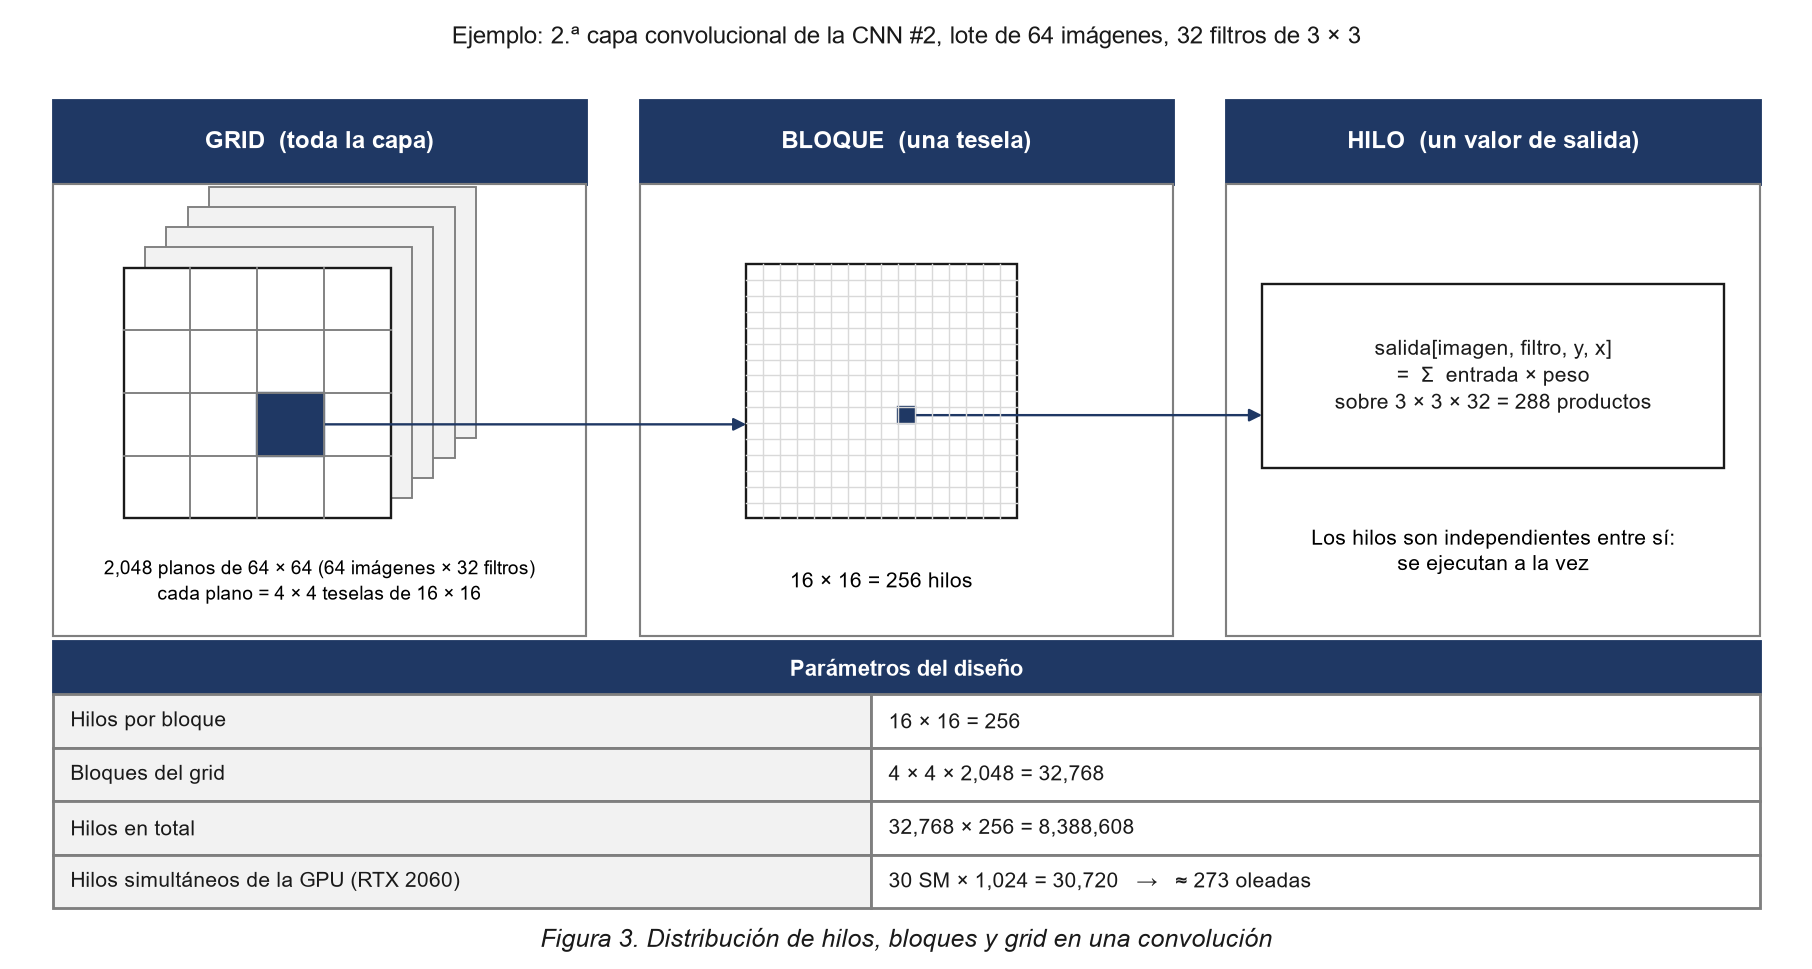



Dimensiones de la **CNN #2**, lote de 64 imágenes:

| Operación | 1 hilo = | Bloque | Grid | Hilos |
|---|---|---|---|---:|
| Convolución 3×3 (capa 2: 32 → 32 canales, 64×64) | un valor de salida (288 productos) | 16 × 16 = 256 | (4, 4, 2048) = 32,768 | 8,388,608 |
| ReLU, Dropout, sumas | un elemento | 256 | 32,768 | 8,388,608 |
| Pooling 2×2 (salida 64×32×32×32) | un valor de salida | 256 | 8,192 | 2,097,152 |
| BatchNorm (32 canales) | un bloque por canal (reducción) | 512 | 32 | 16,384 |
| Capa densa 8192 → 256 | un valor de la matriz resultante (64 × 256) | 16 × 16 = 256 | (16, 4) = 64 | 16,384 |
| Capa densa 256 → 29 | un valor de la matriz resultante (64 × 29) | 16 × 16 = 256 | (2, 4) = 8 | 2,048 |
| Softmax + entropía cruzada | un bloque por imagen | 32 | 64 | 2,048 |
| Retropropagación, entradas | misma geometría que adelante | igual | igual | igual |
| Retropropagación, pesos de una convolución | un bloque por par (filtro, canal de entrada), reduciendo sobre las 262,144 posiciones | 256 | 32 × 32 = 1,024 | 262,144 |
| Adam (2,245,437 parámetros) | un parámetro | 256 | ⌈2,245,437 / 256⌉ = 8,772 | 2,245,437 |

* **Por qué un hilo por valor de salida:** con un hilo por imagen habría solo 64 hilos; la GPU necesita decenas de miles.
* **Por qué bloques de 256 (16 × 16):** es múltiplo de 32 (el *warp*) y forma una tesela cuadrada que permite reutilizar
  la región de entrada en memoria compartida.
* **Capacidad de la GPU (RTX 2060):** 30 multiprocesadores × 1,024 hilos = **30,720 hilos a la vez**. Las convoluciones, el
  pooling y Adam la superan por mucho y la mantienen ocupada; la capa densa final y la pérdida (≈ 2,000 hilos) no la llenan,
  pero pesan muy poco.


In [8]:
mostrar_doc("04_diseno_algoritmo_paralelo.md", desde="Propuesta con CUDA")